# MIR Zarr processing with `spatialmirif`

This notebook follows the pyM²aia-style API, but uses the new standalone
`spatialmirif` package.

NRRD is therefore treated mainly as an import/export format, while MIR
processing is performed directly from the Zarr hypercube.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pprint import pprint
from pathlib import Path

import spatialmirif as smi

print("spatialmirif imported from:")
print(smi.__file__)

from data_path import data_path_zarr_S1_N2, data_path_zarr_S1_N2_info

spatialmirif imported from:
D:\Project_Cemos\pymirifimaging\spatialmirif\spatialmirif\__init__.py


## Load the raw MIR Zarr

The expected raw MIR structure is:

```text
0.zarr/
├── hypercube   # shape (Y, X, spectral_channels)
└── wvnm        # measured wavenumber axis
```

For legacy/raw Zarr data, spatial X/Y pixel size can be read from the slide
`INFO.txt`. `pz` is optional and is only needed when you want the old
single-Z-plane 3D geometry for NRRD/M²aia export.


In [2]:

# Optional Z spacing in micrometres.
# Use None if you only need the normal 2D MIR Zarr workflow.
pz_um = 10.0

I = smi.ZarrSpectrumReader(
    data_path_zarr_S1_N2,
    info_path=data_path_zarr_S1_N2_info,
    pz=pz_um,
)

print("Spectrum Type:", I.GetSpectrumType())
print("Dimensions:", I.GetShape())
print("Pixel Spacing:", I.GetSpacing())
print("Origin:", I.GetOrigin())
print("Direction:", I.GetDirection())
print("Pixels:", I.GetNumberOfSpectra())
print("Spectral Bins:", I.GetXAxisDepth())
print("Wavenumber range:", I.GetXAxis().min(), "to", I.GetXAxis().max(), "cm^-1")
print("First 10 wavenumbers:", I.GetXAxis()[:10])


Spectrum Type: ContinuousProfile
Dimensions: [1560 2400    1]
Pixel Spacing: [0.0043384 0.0043384 0.01     ]
Origin: [0. 0. 0.]
Direction: [1. 0. 0. 0. 1. 0. 0. 0. 1.]
Pixels: 3744000
Spectral Bins: 213
Wavenumber range: 954.0 to 1802.0 cm^-1
First 10 wavenumbers: [954. 958. 962. 966. 970. 974. 978. 982. 986. 990.]


c:\Users\arsla\anaconda3\envs\spatialmirif-dev\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import spatialmirif as mi

I = mi.ZarrSpectrumReader(
    data_path_zarr_S1_N2,
    info_path=data_path_zarr_S1_N2_info,
)

I.info()



spatialmirif — Dataset Information
---------------------------------------------
Name               : 0
Source             : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\0.zarr
Modality           : MIR
Spectrum type      : ContinuousProfile
Dimensions         : [1560, 2400,    1]
Pixel spacing      : [0.004338, 0.004338] mm
Origin             : [0., 0.] mm
Direction          : [1., 0., 0., 1.]
Spectra            : 3744000
Spectral bins      : 213
Wavenumber range   : 954.00 to 1802.00 cm^-1
First 10 wavenumbers: [954., 958., 962., 966., 970., 974., 978., 982., 986., 990.]
Intensity dtype    : float32
Storage            : SpatialData + Dask


In [12]:
# Current MIR-processing settings
print(I.GetParametersAsFormattedString())


normalization=None, pooling=None, image_normalization=MinMax, spectral_selection=Exact, tolerance=25


In [13]:
# Zarr metadata + geometry information
meta_data = I.GetMetaData()
pprint(meta_data)


{'modality': 'MIR', 'spectral_unit': 'cm^-1'}


First 10 x values: [954. 958. 962. 966. 970. 974. 978. 982. 986. 990.]
First 10 y values: [ 0.00482966  0.00763613  0.00893523  0.00577733  0.00093993 -0.00088419
  0.00080972  0.00414843  0.0066547   0.00875112]


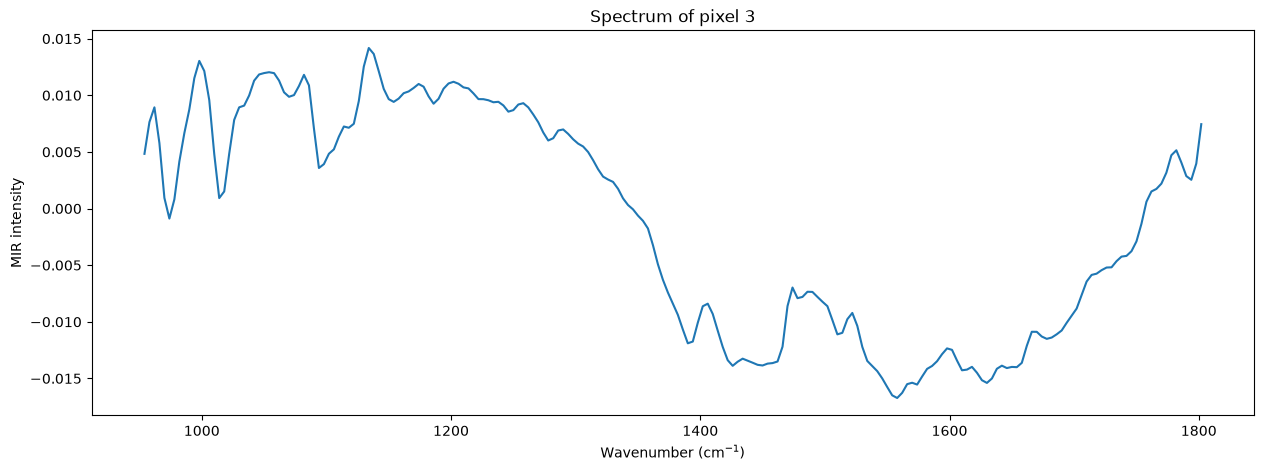

In [6]:
# Plot the spectrum of one pixel
xs, ys = I.GetSpectrum(3)

print("First 10 x values:", xs[:10])
print("First 10 y values:", ys[:10])

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(xs, ys)

ax.set_xlabel("Wavenumber (cm$^{-1}$)")
ax.set_ylabel("MIR intensity")
ax.set_title("Spectrum of pixel 3")

plt.show()


## Nearest spectral channel

`Nearest` selects the measured channel closest to the requested wavenumber.
The hypercube remains in Zarr; only the required data are read for processing.


Requested: 1688 cm^-1
Selected: 1686.0 cm^-1


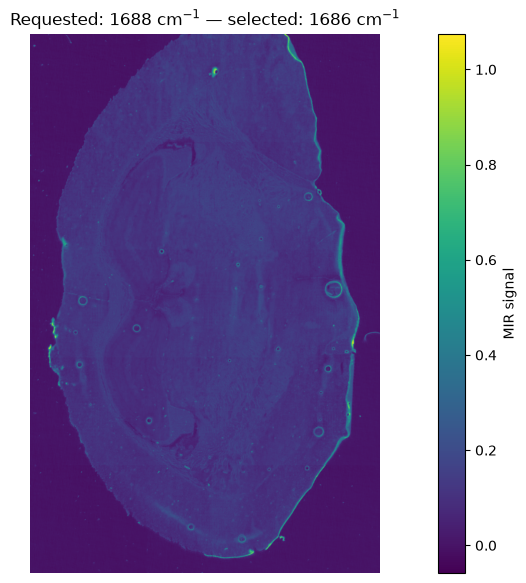

normalization=None, pooling=None, image_normalization=None, spectral_selection=Nearest, tolerance=0


In [7]:
I.SetSpectralSelection("Nearest")
I.SetPooling("None")

requested_wavenumber = 1688

selected = I.GetNearestWavenumber(
    requested_wavenumber
)

image = I.GetArray(
    requested_wavenumber,
    squeeze=True,
)

print("Requested:", requested_wavenumber, "cm^-1")
print("Selected:", selected, "cm^-1")

fig, ax = plt.subplots(figsize=(15, 7))

im = ax.imshow(image)

ax.set_title(
    f"Requested: {requested_wavenumber} cm$^{{-1}}$ "
    f"— selected: {selected:g} cm$^{{-1}}$"
)

ax.axis("off")
plt.colorbar(im, ax=ax, label="MIR signal")
plt.show()

print(I.GetParametersAsFormattedString())


## Exact spectral channel

`Exact` requires the requested wavenumber to exist in `wvnm`.


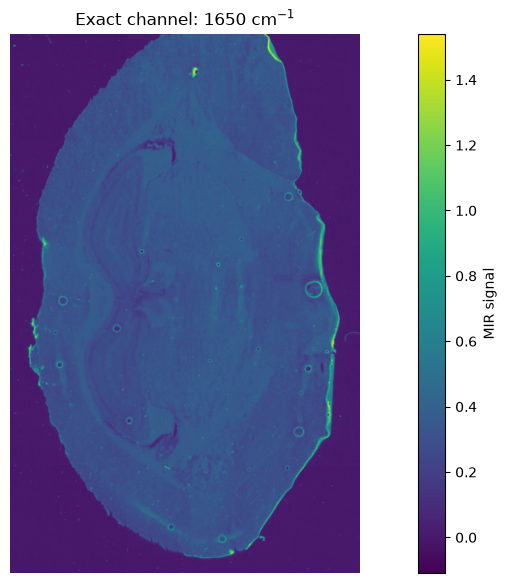

normalization=None, pooling=None, image_normalization=None, spectral_selection=Exact, tolerance=0


In [8]:
I.SetSpectralSelection("Exact")
I.SetPooling("None")

wavenumber = 1650

image = I.GetArray(
    wavenumber,
    squeeze=True,
)

fig, ax = plt.subplots(figsize=(15, 7))

im = ax.imshow(image)
ax.set_title(
    f"Exact channel: {wavenumber} cm$^{{-1}}$"
)
ax.axis("off")

plt.colorbar(im, ax=ax, label="MIR signal")
plt.show()

print(I.GetParametersAsFormattedString())


## Spectral window + pooling

With `Window`, all measured channels inside

```text
center ± tolerance
```

are selected. The pooling strategy determines how those channels are reduced
to one spatial MIR image.


Selected channels:
[1646. 1650. 1654. 1658. 1662. 1666. 1670. 1674. 1678. 1682. 1686. 1690.
 1694.]


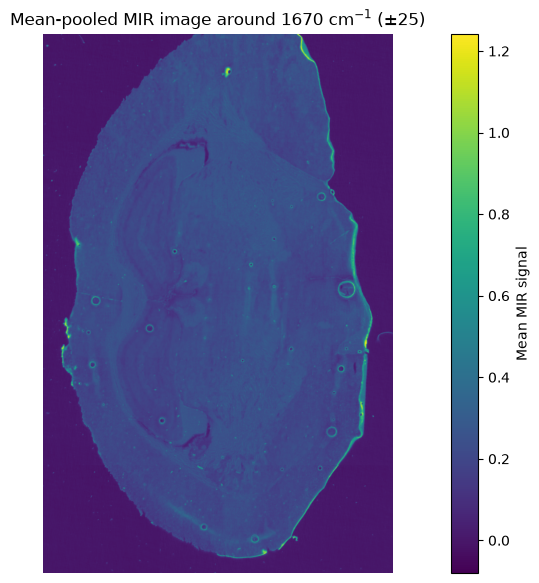

In [9]:
I.SetSpectralSelection("Window")
I.SetTolerance(25)
I.SetPooling("Mean")

requested_wavenumber = 1670

selected_channels = I.GetSelectedWavenumbers(
    requested_wavenumber
)

print("Selected channels:")
print(selected_channels)

image = I.GetArray(
    requested_wavenumber,
    squeeze=True,
)

fig, ax = plt.subplots(figsize=(15, 7))

im = ax.imshow(image)

ax.set_title(
    "Mean-pooled MIR image around "
    f"{requested_wavenumber} cm$^{{-1}}$ "
    f"(±{I.GetTolerance():g})"
)

ax.axis("off")
plt.colorbar(im, ax=ax, label="Mean MIR signal")
plt.show()


## MIR spectrum normalization

The processing classes now live under `pymirimaging.MIRprocessing`, and the
reader exposes the familiar pyM²aia-style setter API.


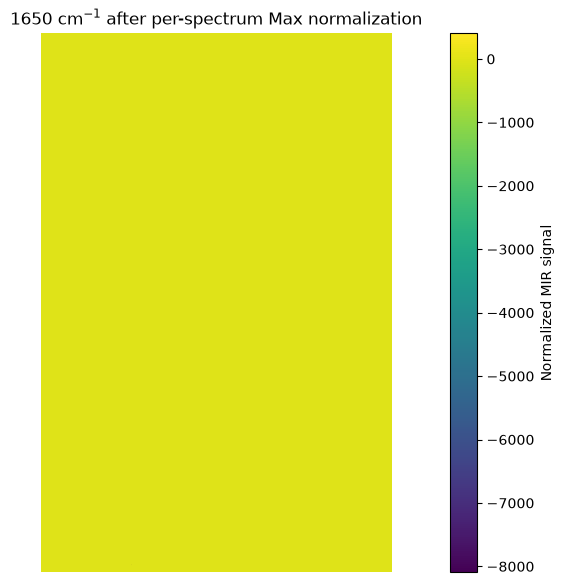

normalization=Max, pooling=None, image_normalization=None, spectral_selection=Exact, tolerance=25


In [10]:
# Example: normalize every MIR spectrum by its maximum.
I.SetNormalization("Max")

# For a single exact image, switch back to exact selection.
I.SetSpectralSelection("Exact")
I.SetPooling("None")

image_1650_normalized = I.GetArray(
    1650,
    squeeze=True,
)

fig, ax = plt.subplots(figsize=(15, 7))
im = ax.imshow(image_1650_normalized)

ax.set_title(
    "1650 cm$^{-1}$ after per-spectrum Max normalization"
)
ax.axis("off")

plt.colorbar(im, ax=ax, label="Normalized MIR signal")
plt.show()

print(I.GetParametersAsFormattedString())



## Image-level MinMax normalization

This happens after the spectral channel has been selected/pooled.


Image shape: (2400, 1560)
Image minimum: 0.0
Image maximum: 1.0


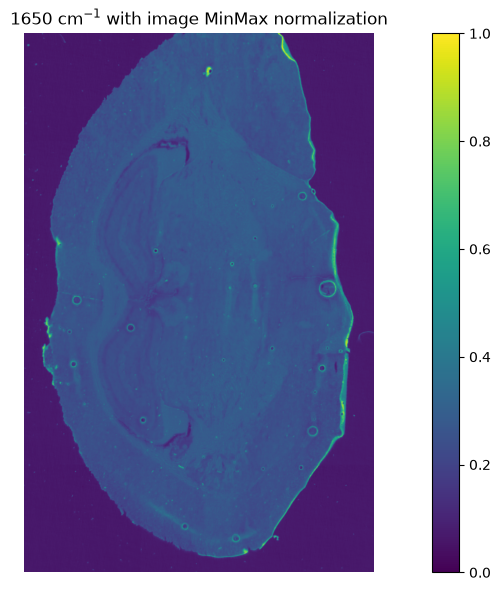

In [11]:
## set back
I.SetNormalization("None")

I.SetImageNormalization("MinMax")

image_1650_minmax = I.GetArray(
    1650,
    squeeze=True,
)

print("Image shape:", image_1650_minmax.shape)
print("Image minimum:", np.nanmin(image_1650_minmax))
print("Image maximum:", np.nanmax(image_1650_minmax))

fig, ax = plt.subplots(figsize=(15, 7))

im = ax.imshow(image_1650_minmax)
ax.set_title(
    "1650 cm$^{-1}$ with image MinMax normalization"
)
ax.axis("off")

plt.colorbar(im, ax=ax)
plt.show()
